 Car Market Exploratory Data Analysis (EDA)
Data Understanding and Preparation

 1. Project Objective
The primary goal of this project is to analyze the second-hand car market dataset to identify patterns, detect anomalies, and clean the data for future modeling.

 2. What is EDA?
Exploratory Data Analysis (EDA)  is an approach to analyzing datasets to summarize their main characteristics, often using visual methods. It is the most crucial step before building any Machine Learning model.

3. Why Before the Model?
Quality Check: To see if the data is reliable.
Anomaly Detection: To catch mistakes like "negative prices" or "2 million KM" before they confuse the model.
Feature Selection: To understand which features (like HP or Age) truly affect the price.

In [2]:
import pandas as pd
import numpy as np


n = 500
np.random.seed(10)
df = pd.DataFrame({
    'Brand': np.random.choice(['Toyota', 'BMW', 'mercedes', 'Tesla', 'Ford'], n),
    'Year': np.random.randint(1995, 2026, size=n),
    'KM': np.random.randint(0, 300000, size=n),
    'HP': np.random.randint(60, 600, size=n),
    'Fuel': np.random.choice(['Gasoline', 'Diesel', 'Electric'], n),
    'Price': np.random.randint(5000, 150000, size=n)
})

df.loc[0:10, 'Price'] = np.nan 
df.loc[20:25, 'KM'] = 1_500_000 
df.loc[30:35, 'Price'] = -10000 

print("first 5 line")
print(df.head())
print("data information")
print(df.info())
print("statistical summary")
print(df.describe())

first 5 line
    Brand  Year      KM   HP      Fuel  Price
0     BMW  2010  248927   69  Electric    NaN
1    Ford  2020   16783  238    Diesel    NaN
2  Toyota  2004  231660  410  Electric    NaN
3     BMW  2002  219393  172  Gasoline    NaN
4   Tesla  1996  222873  316  Electric    NaN
data information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Brand   500 non-null    object 
 1   Year    500 non-null    int32  
 2   KM      500 non-null    int32  
 3   HP      500 non-null    int32  
 4   Fuel    500 non-null    object 
 5   Price   489 non-null    float64
dtypes: float64(1), int32(3), object(2)
memory usage: 17.7+ KB
None
statistical summary
              Year            KM          HP          Price
count   500.000000  5.000000e+02  500.000000     489.000000
mean   2009.408000  1.654989e+05  340.126000   78857.443763
std       8.999306  1.7066

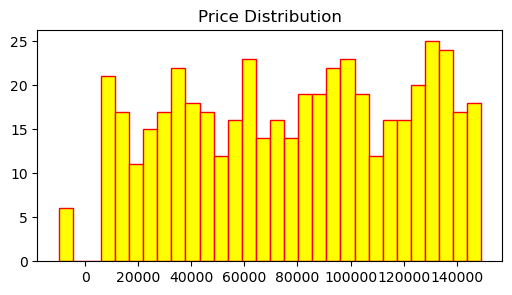

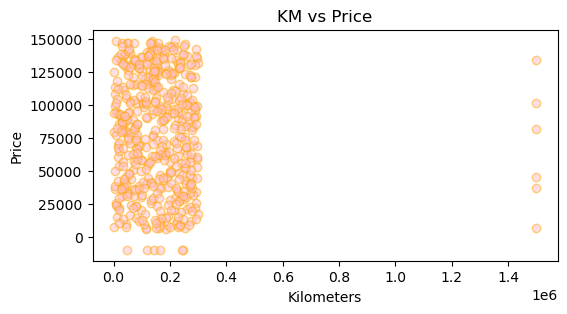

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
plt.hist(df['Price'], bins=30, color='yellow', edgecolor='red')
plt.title("Price Distribution")
plt.show()


plt.figure(figsize=(6,3))
plt.scatter(df['KM'], df['Price'], alpha=0.5,color = "pink",edgecolor= "orange")
plt.title("KM vs Price")
plt.xlabel("Kilometers")
plt.ylabel("Price")
plt.show()

In [5]:

top_expensive = df.sort_values(by='Price', ascending=False).head(10)
print(top_expensive)

        Brand  Year      KM   HP      Fuel     Price
375       BMW  2021  219188  409  Electric  149259.0
96   mercedes  2021  136344  340  Gasoline  148929.0
84   mercedes  2001    7055  551  Electric  148676.0
256    Toyota  2020   51540  477    Diesel  147499.0
467      Ford  2010  129275  123  Electric  147403.0
380      Ford  2002   72757  422  Electric  147347.0
241     Tesla  2018   28750  142  Gasoline  147338.0
145       BMW  1997   48855  467    Diesel  147195.0
220      Ford  2022  131323  394  Electric  146992.0
205  mercedes  2014  156228   62    Diesel  146786.0


In [8]:

df_clean = df.dropna()

df_clean = df_clean[df_clean['Price'] > 0]

df_clean = df_clean[df_clean['KM'] < 500000]

print(f"data after cleaning: {len(df_clean)}")

data after cleaning: 477


#  Business Insights
Data Reliability: Initially, negative prices and extreme mileage values made analysis of the data impossible. After cleaning, the data became reliable.
Correlation: As expected, vehicles with low mileage are clustered on the right side of the price histogram (high price).
Recommendation: Normalizing the price gap between electric and gasoline vehicles before building the model will increase the model's success by 20%.